# Hands-On Session Week2

Homework 2– Temperature and Sampling Efficiency in
Metropolis Monte Carlo

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
## Settings
n_steps = 20000
n_burn = 1000
x0 = 2.5
seed = 504
x_grid = np.linspace(-2.5, 2.5, 1001)

In [3]:
# Setup
def double_well(x):
    return (x**2 - 1.0) **2

def normalize_density(weights,x_grid):
    Z = np.trapz(weights, x_grid)
    return weights / Z

# Lag (denoted as $k$) simply means the gap or distance in steps between two measurements in a sequence.
def autocorrelation(series,max_lag = 200):
    y = np.array(series,dtype=float)
    y = y - np.mean(y)
    variance = np.mean( y **2)

    C = np.empty(max_lag+1)
    C[0] = 1
    for i in range(1,max_lag+1):
        C[i] = np.mean(y[:-i] * y[i:]) / variance
    return C

# lower C (Autocorrelation means better sampling)


## Part 1– How does temperature change equilibrium sampling?

In [28]:
# 1A. Compute and compare observables
def metropolis(n_steps, T, step_size,x0,seed = seed):
    rng = np.random.default_rng(seed)

    x = np.empty(n_steps)
    energy = np.empty(n_steps)
    accepted = np.empty(n_steps, dtype=bool)

    x[0] = x0
    energy[0] = double_well(x0)
    accepted[0] = False

    for n in range(1,n_steps):
        # TODO 1: propose x_trial = x_current + a symmetric random displacement
        x_trial = x[n-1] + rng.uniform(-step_size,step_size)

        # TODO 2: evaluate the trial energy and the energy change
        U_trial = double_well(x_trial)
        delta_U = U_trial - energy[n-1]

        # TODO 3: decide whether the move is accepted
        if delta_U <= 0 :
            accepted[n] = True
            x[n] = x_trial
            energy[n] = U_trial

        else:
            p_acc = np.exp(- delta_U/T)
            if rng.random() < p_acc:
                accepted[n] = True
                x[n] = x_trial
                energy[n] = U_trial
            else:
                accepted[n] = False
                x[n] = x[n-1]
                energy[n] = energy[n-1]

    return x,energy,accepted

temperatures = [0.3,1.0]
result = []
for i in temperatures:
    x,energy,accepted = metropolis(n_steps = n_steps,T = i,step_size = 1,x0 = x0,seed = seed)

    x_prod = x[n_burn:]
    accepted_rate = np.mean(accepted[1:])

    mean_x2_mc = np.mean(x_prod**2)

    U_grid = (x_grid **2 - 1)**2
    weights = np.exp(-U_grid/i)
    Z= np.trapz(weights, x_grid)
    p_t = weights / Z

    mean_x2_ref = np.trapz(x_grid **2 * p_t, x_grid)

    p_bar = np.mean(np.abs(x_prod) <0.3)

    result.append([i,accepted_rate,mean_x2_mc,mean_x2_ref,p_bar])


In [29]:
df = pd.DataFrame(
    result,
    columns=[
        "Temperature",
        "Acceptance fraction",
        "<x^2> MC",
        "<x^2> reference",
        "P(|x| < 0.3)"
    ]
)
df


,Temperature,Acceptance fraction,<x^2> MC,<x^2> reference,P(|x| < 0.3)
0,0.3,0.369518,0.898577,0.899908,0.024526
1,1.0,0.660083,0.838076,0.832745,0.116526


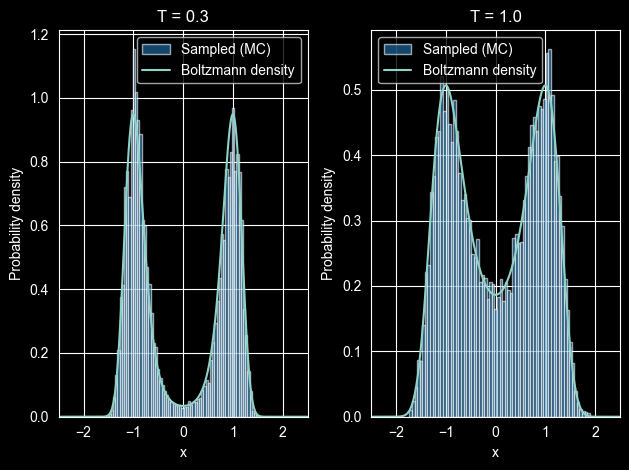

In [26]:
## 1B. Compare sampled and target distributions
# 1B. Compare sampled and target distributions
for j, T in enumerate(temperatures):
    x, energy, accepted = metropolis(n_steps, T, 1, x0, seed)
    x_prod = x[n_burn:]

    U_grid = (x_grid**2 - 1)**2
    weights = np.exp(-U_grid / T)
    Z = np.trapz(weights, x_grid)
    p_t = weights / Z

    plt.subplot(1, 2, j + 1)
    plt.hist(x_prod, bins=70, density=True, color='tab:blue',
             alpha=0.6, label='Sampled (MC)')
    plt.plot(x_grid, p_t, label='Boltzmann density')

    plt.title(f'T = {T}')
    plt.xlabel('x')
    plt.ylabel('Probability density')
    plt.xlim(-2.5, 2.5)
    plt.legend()

plt.tight_layout()
plt.show()


#### 1C. Interpretation

(a) How and why does sampling of the barrier neighborhood change between the two temperatures?
Refer to your actual results

At \(T=0.3\), the probability of sampling the barrier region \((|x|<0.3)\) is only 0.0245 (2.45%). At \(T=1.0\), it increases to 0.1165 (11.65%). Higher temperature makes it easier for the system to overcome the energy barrier between the two wells, so it visits the barrier region more often.

(b) Why can the two distributions differ even though U(x) has not changed?

Monte Carlo has a finite number of steps, and at low temperature, the system may rarely cross the energy barrier between the two wells. Therefore, it may not sample both wells equally or explore the full distribution.




## Part 2– Why does high acceptance not guarantee efficient sampling?

In [30]:
step_size = np.array([0.05,1.0,30.0])

In [32]:
## 2A. Compare basic diagnostics
result_2=[]
for i in step_size:
    x,energy,accepted = metropolis(
        n_steps = n_steps,
        T = 0.5,
        step_size = i,
        x0 = x0,
        seed = seed

    )

    x_prod = x[n_burn:]
    accepted_rate = np.mean(accepted[1:])

    # Count switches between negative and positive x
    switches = np.sum(np.sign(x_prod[1:]) != np.sign(x_prod[:-1]))

    C = autocorrelation(x_prod, max_lag=20)
    Cx20 = C[20]

    result_2.append([i,accepted_rate,switches,Cx20])

df_2A = pd.DataFrame(
    result_2,
    columns=[
        "Proposal width",
        "Acceptance fraction",
        "Sign switches",
        "Cx(20)"
    ]
)

df_2A





,Proposal width,Acceptance fraction,Sign switches,Cx(20)
0,0.05,0.967398,10,0.870393
1,1.00,0.512226,1124,0.303830
2,30.00,0.032502,305,0.530644


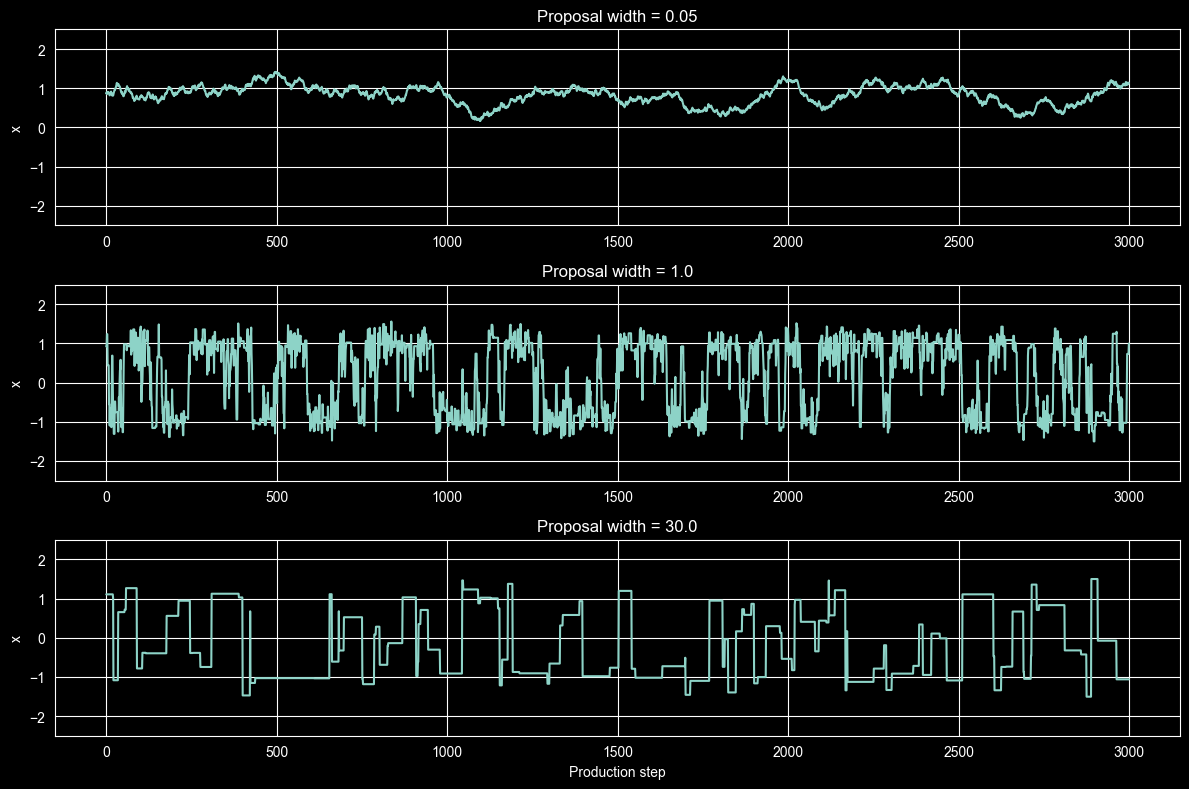

In [39]:
plt.figure(figsize=(12, 8))

step_size = [0.05, 1.0, 30.0]

for j, width in enumerate(step_size):
    x, energy, accepted = metropolis(
        n_steps=n_steps,
        T=0.5,
        step_size=width,
        x0=x0,
        seed=seed
    )

    x_prod = x[n_burn:]

    plt.subplot(3, 1, j + 1)
    plt.plot(x_prod[:3000])
    plt.title(f'Proposal width = {width}')
    plt.ylabel('x')
    plt.ylim(-2.5, 2.5)

plt.xlabel('Production step')
plt.tight_layout()
plt.show()

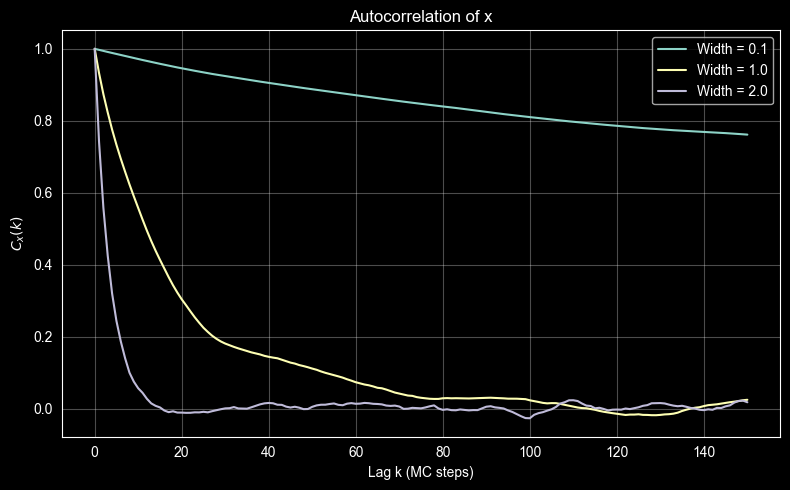

In [43]:
# 2C. Autocorrelation of x

plt.figure(figsize=(8, 5))

step_sizes = [0.1, 1.0, 2.0]

for width in step_sizes:
    x, energy, accepted = metropolis(
        n_steps=n_steps,
        T=0.5,
        step_size=width,
        x0=x0,
        seed=seed
    )

    x_prod = x[n_burn:]
    Cx = autocorrelation(x_prod, max_lag=150)

    plt.plot(range(151), Cx, label=f'Width = {width}')

plt.xlabel('Lag k (MC steps)')
plt.ylabel(r'$C_x(k)$')
plt.title('Autocorrelation of x')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Width = 0.05, Acceptance rate  = 0.967
Width = 1.0, Acceptance rate  = 0.512
Width = 30.0, Acceptance rate  = 0.033


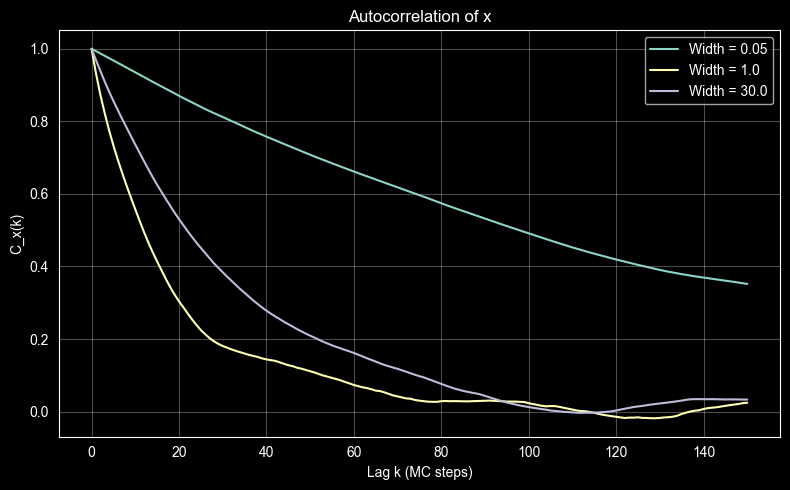

In [49]:
# 2C. Autocorrelation of x + acceptance rate for first 30 steps

plt.figure(figsize=(8, 5))

step_sizes = [0.05, 1.0, 30.0]

for width in step_sizes:
    x, energy, accepted = metropolis(
        n_steps=n_steps,
        T=0.5,
        step_size=width,
        x0=x0,
        seed=seed
    )

    acceptance_rate = np.mean(accepted[1:])
    print(f'Width = {width}, Acceptance rate  = {acceptance_rate:.3f}')

    x_prod = x[n_burn:]
    Cx = autocorrelation(x_prod, max_lag=150)

    plt.plot(range(151), Cx, label=f'Width = {width}')

plt.xlabel('Lag k (MC steps)')
plt.ylabel(r'C_x(k)')
plt.title('Autocorrelation of x')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 2D. Interpretation

(a) Why can tiny proposals produce strong correlation despite high acceptance? Why can extremely
large proposals also produce strong correlation

Tiny proposals: They are accepted frequently, but each move changes \(x\) only slightly, so the system explores the state space slowly and consecutive samples remain highly correlated.

Extremely large proposals: They are often rejected because they increase the energy too much. The system stays at the same position for many steps, causing strong correlation.


(b) Which of the three proposal widths is most effective for this experiment? Support your answer
with acceptance, exploration, and autocorrelation, not acceptance alone

The proposal width of 1.0 is likely the most effective. Width 0.05 has high acceptance but moves too slowly, leading to strong correlation. Width 30.0 produces extremely large jumps that are usually rejected, reducing exploration and keeping the system at the same position. Width 1.0 offers a better balance of acceptance, exploration between the two wells, and lower autocorrelation.


(c) What does it mean physically and statistically if Cx(k) decays slowly?

Physically: The system retains memory of its previous positions and moves slowly between states or wells.

Statistically: Consecutive samples are highly correlated, so the effective number of independent samples is smaller, increasing uncertainty in estimated averages.




